# 07 · Release-decision engine: seeded-fault evaluation (E4/E7, v1.2)
**Supports:** RQ4 (false assurance), recommendations P0-01, P0-02 and P0-04. Each of 37 synthetic faults is planted, one at a time, into a valid **synthetic** bundle. Every faulty bundle is then evaluated by the v1.2 engine (`crasme.gate`) and by the legacy v1.1 CI gate.
*This verifies engine logic against anticipated faults. It does not estimate real-world fault prevalence.*

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme.mutation import run_suite
res = run_suite()
pd.Series(res['summary'])

baseline_decision               PASS
baseline_reasons                  []
mutations                         37
false_green                        0
false_green_rate                 0.0
decision_match_rate              1.0
correct_code_rate                1.0
freshness_recall                 1.0
legacy_v11_false_green            33
legacy_v11_false_green_rate    0.892
legacy_v11_freshness_recall      0.0
dtype: object

In [2]:
df = pd.DataFrame(res['rows'])
tab = df.groupby('category').agg(n=('mutation','count'), v12_false_green=('false_green','sum'),
                                 v11_false_green=('legacy_v11_false_green','sum'), v12_code_ok=('code_reported','sum'))
tab

,n,v12_false_green,v11_false_green,v12_code_ok
category,,,,
approval,4,0,4,4
bundle,2,0,2,2
evidence,9,0,9,9
finding,4,0,1,4
obligation,7,0,7,7
scan,11,0,10,11


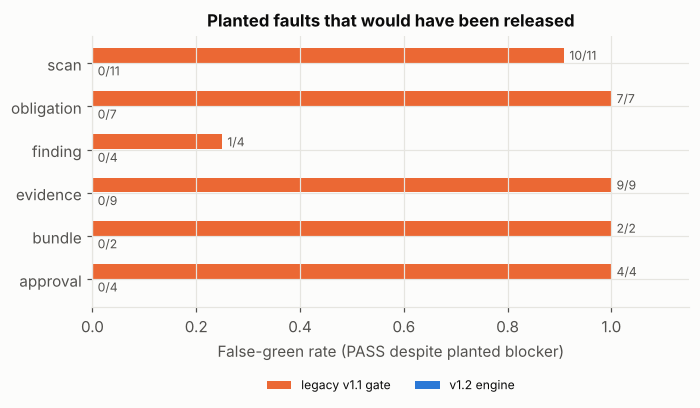

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(tab))
ax.barh(y + 0.18, tab.v11_false_green / tab.n, height=0.34, color=plotting.SERIES[1], label='legacy v1.1 gate')
ax.barh(y - 0.18, tab.v12_false_green / tab.n, height=0.34, color=plotting.SERIES[0], label='v1.2 engine')
for i, (a, b, n) in enumerate(zip(tab.v12_false_green, tab.v11_false_green, tab.n)):
    ax.text(b / n + 0.01, i + 0.18, f'{b}/{n}', va='center', fontsize=8, color=plotting.INK2)
    ax.text(a / n + 0.01, i - 0.18, f'{a}/{n}', va='center', fontsize=8, color=plotting.INK2)
ax.set_yticks(y, tab.index); ax.set_xlim(0, 1.15); ax.set_xlabel('False-green rate (PASS despite planted blocker)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8); ax.set_title('Planted faults that would have been released'); plt.show()

In [4]:
df[['mutation','category','description','decision','expected_code','legacy_v11_decision']]

,mutation,category,description,decision,expected_code,legacy_v11_decision
0,M01,scan,KEV feed download failed (curl error),REVIEW_REQUIRED,KEV_FEED_UNAVAILABLE,PASS
1,M02,scan,KEV feed empty (v1.1 fallback {'vulnerabilitie...,REVIEW_REQUIRED,KEV_FEED_UNAVAILABLE,PASS
2,M03,scan,KEV feed truncated (count mismatch),REVIEW_REQUIRED,KEV_FEED_UNAVAILABLE,PASS
3,M04,scan,Vulnerability scanner exited with error code 2,REVIEW_REQUIRED,SCAN_FAILED,PASS
4,M05,scan,Vulnerability scanner output file missing,REVIEW_REQUIRED,SCAN_OUTPUT_MISSING,PASS
5,M06,scan,Trivy JSON truncated/malformed,REVIEW_REQUIRED,SCAN_OUTPUT_INVALID,ERROR
6,M07,scan,SBOM generator produced an empty SBOM,REVIEW_REQUIRED,SCAN_OUTPUT_INVALID,PASS
7,M08,scan,Required scan never recorded,REVIEW_REQUIRED,SCAN_NOT_RECORDED,PASS
8,M09,scan,Scan-status manifest from another build,REVIEW_REQUIRED,SCAN_MANIFEST_WRONG_BUILD,PASS
9,M10,scan,Scan output edited after recording,FAIL,SCAN_OUTPUT_TAMPERED,PASS


**Reading.** v1.1 blocked only on KEV hits and treated missing or empty inputs as clean. As a result, 33 of 37 planted blockers would have passed, including every stale-evidence case. v1.2 detects all 37 faults, with the expected FAIL/REVIEW split and reason code in each case.

**Next (pilot E4):**
- apply the same mutation operators to forks of pilot repositories
- measure reviewer time per evidence package
- add faults the authors did *not* anticipate, contributed by external reviewers